# Análise exploratória — Diabetes Health Indicators (BRFSS 2015)

Este notebook investiga os dados **antes** de qualquer modelagem. O objetivo é
entender quem são as pessoas da pesquisa, a qualidade dos dados, como o
diabetes se distribui entre grupos e quais perfis concentram mais risco.

**Como ler:** cada seção começa explicando *o que* vamos olhar e *por que*
importa. Depois vem o código e o resultado, e por fim um bloco
**📌 O que observamos** com a interpretação em linguagem simples.

| # | Seção | Pergunta que responde |
|---|---|---|
| 1 | [Dados e dicionário](#1.-Os-dados) | O que cada coluna significa? |
| 2 | [Qualidade dos dados](#2.-Qualidade-dos-dados) | Há nulos, duplicados, rótulos conflitantes, valores estranhos? |
| 3 | [A variável alvo](#3.-A-variável-alvo) | Quantas pessoas têm diabetes ou pré-diabetes? |
| 4 | [Retrato da população](#4.-Retrato-da-população) | Como as características se distribuem? |
| 5 | [Agrupamentos e fatores de risco](#5.-Agrupamentos:-onde-o-diabetes-se-concentra) | Em quais grupos o diabetes é mais comum? |
| 6 | [Correlações](#6.-Correlações-e-associações) | Quais variáveis andam juntas e quais mais informam sobre o alvo? |
| 7 | [Perfis](#7.-Perfis-de-pessoas) | Existem "tipos" de pessoas? Quais combinações concentram risco? |
| 8 | [Conclusões](#8.-Conclusões-e-implicações) | O que isso muda na modelagem? |

> ⚠️ **Associação não é causalidade.** Os dados são de uma pesquisa transversal
> e autodeclarada. Quando dizemos que um grupo "tem mais diabetes", não
> significa que a característica *cause* diabetes (veja a seção 5.1 para
> exemplos claros disso).

## Principais achados (resumo executivo)

1. **A base é desbalanceada:** 84,2% sem diabetes, 13,9% com diabetes e apenas
   **1,8% com pré-diabetes**, uma classe pequena demais para ser modelada isoladamente.
2. **23.899 linhas (9,4%) são cópias exatas de outras.** Quase todas (99%) são
   de pessoas **sem diabetes, jovens e saudáveis**: com poucas respostas possíveis,
   pessoas diferentes acabam com respostas idênticas. Removê-las muda a
   prevalência de 15,8% para 17,3%.
3. **1.834 perfis idênticos têm rótulos diferentes** (mesmas respostas, um tem
   diabetes e outro não): há um limite de acerto que nenhum modelo supera.
4. **Os fatores mais associados** ao diabetes são pressão alta (3,8× mais
   prevalência), saúde geral ruim (13× entre "excelente" e "ruim"), idade,
   colesterol alto, IMC e dificuldade de andar.
5. **Há um forte gradiente socioeconômico:** a prevalência cai de ~28% nas menores
   rendas para 9% na maior.
6. **Alguns padrões são efeito do diagnóstico, não causa:** quem bebe muito tem
   *menos* diabetes, e quem checou o colesterol tem 5× mais. São pistas de
   **causalidade reversa** e de **viés de seleção**.
7. **Não há grupos naturais bem separados** (os dados formam um contínuo), mas
   uma segmentação em 4 perfis vai de **5% a 37%** de prevalência, e regras
   simples isolam um segmento com **50%** (pressão alta + saúde regular/ruim + sobrepeso).

## 0. Preparação do ambiente

Importamos as bibliotecas e reutilizamos as definições de colunas do próprio
projeto (`diabetes_risk.domain.schemas`). Assim, o notebook e o pipeline usam
a mesma fonte da verdade sobre os dados.

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

from diabetes_risk.domain.schemas import (
    BINARY_FEATURES,
    FEATURE_COLUMNS,
    NUMERIC_FEATURES,
    RAW_SCHEMA,
    TARGET_COLUMN,
)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 72, "axes.titleweight": "bold", "axes.titlesize": 12})
pd.set_option("display.max_columns", 40)

# Raiz do projeto: sobe diretórios até achar o params.yaml (funciona de qualquer pasta).
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "params.yaml").exists())
DATA_PATH = ROOT / "data" / "raw" / "diabetes_012_health_indicators_BRFSS2015.csv"
SEED = 42

### Rótulos legíveis

As respostas vêm codificadas como números (ex.: `Age = 9`). Para os gráficos
ficarem compreensíveis, traduzimos os códigos com base no *codebook* do BRFSS.

In [ ]:
CLASSES = {0: "Sem diabetes", 1: "Pré-diabetes", 2: "Diabetes"}
CLASS_ORDER = list(CLASSES.values())
CLASS_COLORS = {"Sem diabetes": "#4C72B0", "Pré-diabetes": "#DD8452", "Diabetes": "#C44E52"}

AGE_LABELS = {
    1: "18-24",
    2: "25-29",
    3: "30-34",
    4: "35-39",
    5: "40-44",
    6: "45-49",
    7: "50-54",
    8: "55-59",
    9: "60-64",
    10: "65-69",
    11: "70-74",
    12: "75-79",
    13: "80+",
}
GENHLTH_LABELS = {1: "Excelente", 2: "Muito boa", 3: "Boa", 4: "Regular", 5: "Ruim"}
EDUCATION_LABELS = {
    1: "Nunca estudou",
    2: "Fund. incompleto",
    3: "Médio incompleto",
    4: "Médio completo",
    5: "Superior incompleto",
    6: "Superior completo",
}
INCOME_LABELS = {
    1: "< $10 mil",
    2: "$10-15 mil",
    3: "$15-20 mil",
    4: "$20-25 mil",
    5: "$25-35 mil",
    6: "$35-50 mil",
    7: "$50-75 mil",
    8: "≥ $75 mil",
}
ORDINAL_LABELS = {
    "Age": AGE_LABELS,
    "GenHlth": GENHLTH_LABELS,
    "Education": EDUCATION_LABELS,
    "Income": INCOME_LABELS,
}

BMI_BINS = [0, 18.5, 25, 30, 35, 40, np.inf]
BMI_LABELS = [
    "Abaixo do peso",
    "Normal",
    "Sobrepeso",
    "Obesidade I",
    "Obesidade II",
    "Obesidade III",
]

DESCRICAO = {
    "HighBP": "Pressão alta",
    "HighChol": "Colesterol alto",
    "CholCheck": "Checou colesterol (5 anos)",
    "BMI": "IMC",
    "Smoker": "Fumante (100+ cigarros na vida)",
    "Stroke": "Já teve AVC",
    "HeartDiseaseorAttack": "Doença cardíaca/infarto",
    "PhysActivity": "Atividade física (30 dias)",
    "Fruits": "Come frutas diariamente",
    "Veggies": "Come vegetais diariamente",
    "HvyAlcoholConsump": "Consumo pesado de álcool",
    "AnyHealthcare": "Tem plano/cobertura de saúde",
    "NoDocbcCost": "Deixou de ir ao médico pelo custo",
    "GenHlth": "Saúde geral (autoavaliação)",
    "MentHlth": "Dias de saúde mental ruim",
    "PhysHlth": "Dias de saúde física ruim",
    "DiffWalk": "Dificuldade para andar",
    "Sex": "Sexo masculino",
    "Age": "Faixa etária",
    "Education": "Escolaridade",
    "Income": "Renda anual",
}

### Funções auxiliares

`prevalencia()` é a ferramenta central da análise: para cada grupo, mostra
quantas pessoas existem e qual porcentagem tem diabetes ou pré-diabetes.

In [ ]:
def prevalencia(data: pd.DataFrame, by: str | list[str]) -> pd.DataFrame:
    # Tamanho do grupo e % de pessoas com risco (pré-diabetes ou diabetes).
    grouped = data.groupby(by, observed=True)
    return pd.DataFrame(
        {
            "pessoas": grouped.size(),
            "% da base": grouped.size() / len(data),
            "% com risco": grouped["tem_risco"].mean(),
            "% diabetes": grouped[TARGET_COLUMN].apply(lambda s: (s == 2).mean()),
            "% pré-diabetes": grouped[TARGET_COLUMN].apply(lambda s: (s == 1).mean()),
        }
    )


def formatar(tabela: pd.DataFrame, gradiente: str | None = "% com risco"):
    # Formata porcentagens e destaca a coluna de risco com um degradê.
    fmt = {c: "{:.1%}" for c in tabela.columns if c.startswith("%")}
    fmt.update({c: "{:,.0f}" for c in tabela.columns if c in ("pessoas", "linhas")})
    fmt.update(
        {
            c: "{:.2f}"
            for c in tabela.columns
            if c not in fmt and pd.api.types.is_float_dtype(tabela[c])
        }
    )
    styled = tabela.style.format(fmt)
    if gradiente in tabela.columns:
        styled = styled.background_gradient(subset=[gradiente], cmap="Reds")
    return styled


def rotular_barras(ax, fmt="{:.0%}", **kwargs):
    for container in ax.containers:
        ax.bar_label(
            container,
            fmt=fmt.format if isinstance(fmt, str) else fmt,
            padding=2,
            fontsize=9,
            **kwargs,
        )

## 1. Os dados

O **BRFSS** (*Behavioral Risk Factor Surveillance System*) é uma pesquisa
telefônica anual do CDC (EUA) sobre saúde e comportamento. Esta versão, de 2015,
foi limpa e disponibilizada no Kaggle com **21 indicadores** e o alvo
`Diabetes_012`.

### Dicionário de dados

| Coluna | Tipo | Significado | Valores |
|---|---|---|---|
| `Diabetes_012` | alvo | Diagnóstico de diabetes | 0 = não, 1 = pré-diabetes, 2 = diabetes |
| `HighBP` | binária | Já foi diagnosticado com pressão alta | 0/1 |
| `HighChol` | binária | Já foi diagnosticado com colesterol alto | 0/1 |
| `CholCheck` | binária | Checou o colesterol nos últimos 5 anos | 0/1 |
| `BMI` | numérica | Índice de massa corporal (peso/altura²) | 12–98 |
| `Smoker` | binária | Fumou ao menos 100 cigarros na vida | 0/1 |
| `Stroke` | binária | Já teve AVC | 0/1 |
| `HeartDiseaseorAttack` | binária | Doença coronariana ou infarto | 0/1 |
| `PhysActivity` | binária | Atividade física nos últimos 30 dias (fora do trabalho) | 0/1 |
| `Fruits` / `Veggies` | binária | Consome frutas / vegetais 1+ vez ao dia | 0/1 |
| `HvyAlcoholConsump` | binária | Consumo pesado (homens >14 doses/semana, mulheres >7) | 0/1 |
| `AnyHealthcare` | binária | Possui algum plano ou cobertura de saúde | 0/1 |
| `NoDocbcCost` | binária | Deixou de ir ao médico no último ano por causa do custo | 0/1 |
| `GenHlth` | ordinal | Como avalia a própria saúde | 1 = excelente … 5 = ruim |
| `MentHlth` | contagem | Dias de saúde mental ruim nos últimos 30 | 0–30 |
| `PhysHlth` | contagem | Dias de saúde física ruim nos últimos 30 | 0–30 |
| `DiffWalk` | binária | Dificuldade séria para andar ou subir escadas | 0/1 |
| `Sex` | binária | Sexo | 0 = feminino, 1 = masculino |
| `Age` | ordinal | Faixa etária de 5 anos | 1 = 18–24 … 13 = 80+ |
| `Education` | ordinal | Escolaridade | 1 = nunca estudou … 6 = superior completo |
| `Income` | ordinal | Renda anual do domicílio | 1 = < US$ 10 mil … 8 = ≥ US$ 75 mil |

Todas as informações são **autodeclaradas** pelo entrevistado.

In [ ]:
raw = pd.read_csv(DATA_PATH)

df = raw.copy()
df["classe"] = pd.Categorical(df[TARGET_COLUMN].map(CLASSES), categories=CLASS_ORDER, ordered=True)
df["tem_risco"] = (df[TARGET_COLUMN] > 0).astype(int)  # pré-diabetes ou diabetes
df["faixa_imc"] = pd.cut(df["BMI"], bins=BMI_BINS, labels=BMI_LABELS, right=False)
for col, labels in ORDINAL_LABELS.items():
    df[f"{col}_rotulo"] = pd.Categorical(
        df[col].map(labels), categories=list(labels.values()), ordered=True
    )

print(
    f"{raw.shape[0]:,} pessoas × {raw.shape[1]} colunas  |  memória: {raw.memory_usage(deep=True).sum() / 1e6:.1f} MB"
)
raw.head()

253,680 pessoas × 22 colunas  |  memória: 44.6 MB


,Diabetes_012,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,HvyAlcoholConsump,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


In [ ]:
resumo = pd.DataFrame(
    {
        "descrição": [DESCRICAO.get(c, "Alvo") for c in raw.columns],
        "tipo": raw.dtypes.astype(str),
        "valores distintos": raw.nunique(),
        "mínimo": raw.min(),
        "máximo": raw.max(),
        "média": raw.mean().round(2),
        "nulos": raw.isna().sum(),
    }
)
resumo

,descrição,tipo,valores distintos,mínimo,máximo,média,nulos
Diabetes_012,Alvo,float64,3,0.0,2.0,0.30,0
HighBP,Pressão alta,float64,2,0.0,1.0,0.43,0
HighChol,Colesterol alto,float64,2,0.0,1.0,0.42,0
CholCheck,Checou colesterol (5 anos),float64,2,0.0,1.0,0.96,0
BMI,IMC,float64,84,12.0,98.0,28.38,0
Smoker,Fumante (100+ cigarros na vida),float64,2,0.0,1.0,0.44,0
Stroke,Já teve AVC,float64,2,0.0,1.0,0.04,0
HeartDiseaseorAttack,Doença cardíaca/infarto,float64,2,0.0,1.0,0.09,0
PhysActivity,Atividade física (30 dias),float64,2,0.0,1.0,0.76,0
Fruits,Come frutas diariamente,float64,2,0.0,1.0,0.63,0


📌 **O que observamos**

- São **253.680 pessoas** e **22 colunas**, todas numéricas (`float64`), sem nenhum valor nulo.
- A maioria das variáveis é **binária** (só 0 ou 1). Apenas `BMI`, `MentHlth` e
  `PhysHlth` têm muitos valores distintos. Isso vai ser importante para
  entender os duplicados.
- Os mínimos e máximos batem com o dicionário. A seguir validamos isso formalmente.

## 2. Qualidade dos dados

Antes de tirar conclusões, precisamos confiar nos dados. Verificamos quatro coisas:

1. **Contrato:** todas as colunas existem, sem nulos e dentro da faixa válida?
2. **Duplicados:** há linhas idênticas? Por quê? Elas atrapalham?
3. **Rótulos conflitantes:** pessoas com respostas idênticas têm diagnósticos diferentes?
4. **Valores extremos e padrões de resposta:** há valores implausíveis ou "arredondados"?

### 2.1 Validação do contrato

Usamos o mesmo schema (Pandera) que o pipeline usa na ingestão.

In [ ]:
RAW_SCHEMA.validate(raw, lazy=True)
print("✅ Todas as 22 colunas presentes, sem nulos e dentro das faixas do codebook.")

✅ Todas as 22 colunas presentes, sem nulos e dentro das faixas do codebook.


### 2.2 Linhas duplicadas

Uma linha duplicada é uma pessoa cujas **22 respostas são exatamente iguais**
às de outra. Pode ser erro (registro repetido) ou coincidência (pessoas
diferentes com as mesmas respostas). Vamos medir e investigar.

In [ ]:
copias_extras = raw.duplicated()  # 2ª, 3ª... ocorrência de cada linha repetida
envolvidas = raw.duplicated(keep=False)  # todas as linhas que têm ao menos uma "gêmea"
tamanho_grupo = raw.groupby(list(raw.columns)).size()

print(
    f"Cópias extras (removíveis):      {copias_extras.sum():>7,}  ({copias_extras.mean():.1%} da base)"
)
print(f"Linhas envolvidas em repetição:  {envolvidas.sum():>7,}  ({envolvidas.mean():.1%})")
print(f"Perfis distintos que se repetem: {(tamanho_grupo > 1).sum():>7,}")
print(f"Maior repetição de um mesmo perfil: {tamanho_grupo.max()} vezes")

Cópias extras (removíveis):       23,899  (9.4% da base)
Linhas envolvidas em repetição:   35,086  (13.8%)
Perfis distintos que se repetem:  11,187
Maior repetição de um mesmo perfil: 59 vezes


**Quantas vezes cada perfil repetido aparece?** A maioria se repete só 2 ou 3
vezes; poucos perfis aparecem dezenas de vezes.

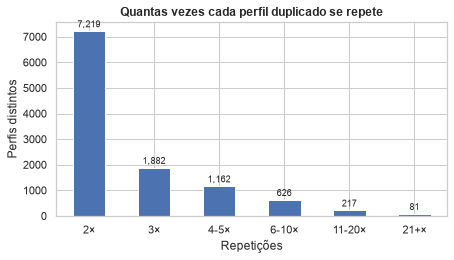

In [ ]:
repeticoes = tamanho_grupo[tamanho_grupo > 1]
faixas = pd.cut(
    repeticoes,
    bins=[1, 2, 3, 5, 10, 20, 100],
    labels=["2×", "3×", "4-5×", "6-10×", "11-20×", "21+×"],
)

fig, ax = plt.subplots(figsize=(7, 3.5))
faixas.value_counts().sort_index().plot.bar(ax=ax, color="#4C72B0", rot=0)
rotular_barras(ax, fmt="{:,.0f}")
ax.set(
    title="Quantas vezes cada perfil duplicado se repete",
    xlabel="Repetições",
    ylabel="Perfis distintos",
)
plt.show()

**Quem são os perfis mais repetidos?** Mostramos os 5 primeiros com rótulos legíveis.

In [ ]:
top = tamanho_grupo.sort_values(ascending=False).head(5).reset_index(name="repetições")
legivel = top.assign(
    classe=top[TARGET_COLUMN].map(CLASSES),
    idade=top["Age"].map(AGE_LABELS),
    saude=top["GenHlth"].map(GENHLTH_LABELS),
    renda=top["Income"].map(INCOME_LABELS),
    escolaridade=top["Education"].map(EDUCATION_LABELS),
)
cols_risco = ["HighBP", "HighChol", "Smoker", "Stroke", "HeartDiseaseorAttack", "DiffWalk"]
legivel["fatores de risco"] = top[cols_risco].sum(axis=1).astype(int)
legivel[
    [
        "repetições",
        "classe",
        "idade",
        "Sex",
        "BMI",
        "saude",
        "PhysActivity",
        "MentHlth",
        "PhysHlth",
        "fatores de risco",
        "renda",
        "escolaridade",
    ]
]

,repetições,classe,idade,Sex,BMI,saude,PhysActivity,MentHlth,PhysHlth,fatores de risco,renda,escolaridade
0,59,Sem diabetes,45-49,0.0,21.0,Excelente,1.0,0.0,0.0,0,≥ $75 mil,Superior completo
1,55,Sem diabetes,45-49,0.0,23.0,Excelente,1.0,0.0,0.0,0,≥ $75 mil,Superior completo
2,53,Sem diabetes,50-54,0.0,23.0,Excelente,1.0,0.0,0.0,0,≥ $75 mil,Superior completo
3,52,Sem diabetes,45-49,0.0,22.0,Excelente,1.0,0.0,0.0,0,≥ $75 mil,Superior completo
4,52,Sem diabetes,40-44,0.0,21.0,Excelente,1.0,0.0,0.0,0,≥ $75 mil,Superior completo


**Os duplicados são iguais entre as classes?** Comparamos a taxa de
duplicação dentro de cada classe e o perfil médio de quem é duplicado.

In [ ]:
dup = df.assign(duplicada=copias_extras)
por_classe = dup.groupby("classe", observed=True)["duplicada"].agg(["sum", "mean"])
por_classe.columns = ["cópias extras", "% da classe que é cópia"]
display(por_classe.style.format({"cópias extras": "{:,.0f}", "% da classe que é cópia": "{:.2%}"}))

comparacao = pd.DataFrame(
    {
        "linhas com gêmeas": df[envolvidas][list(FEATURE_COLUMNS)].mean(),
        "linhas únicas": df[~envolvidas][list(FEATURE_COLUMNS)].mean(),
    }
).rename(index=DESCRICAO)
comparacao["diferença"] = comparacao["linhas com gêmeas"] - comparacao["linhas únicas"]
comparacao.sort_values("diferença").round(2)

,cópias extras,% da classe que é cópia
classe,,
Sem diabetes,"23,648",11.07%
Pré-diabetes,2,0.04%
Diabetes,249,0.70%


,linhas com gêmeas,linhas únicas,diferença
Dias de saúde física ruim,0.10,4.91,-4.81
Dias de saúde mental ruim,0.13,3.68,-3.55
IMC,25.66,28.82,-3.16
Saúde geral (autoavaliação),1.70,2.64,-0.94
Faixa etária,7.61,8.10,-0.49
Pressão alta,0.21,0.46,-0.26
Fumante (100+ cigarros na vida),0.25,0.47,-0.22
Dificuldade para andar,0.00,0.19,-0.19
Colesterol alto,0.27,0.45,-0.17
Doença cardíaca/infarto,0.01,0.11,-0.10


**Por que tantas coincidências?** Calculamos quantas combinações de respostas
são *teoricamente* possíveis e quantas de fato aparecem.

In [ ]:
combinacoes = np.prod([float(raw[c].nunique()) for c in FEATURE_COLUMNS])
print(f"Combinações teoricamente possíveis: {combinacoes:.2e}")
print(
    f"Combinações distintas observadas:   {raw[list(FEATURE_COLUMNS)].drop_duplicates().shape[0]:,}"
)

prev_antes, prev_depois = df["tem_risco"].mean(), df[~copias_extras]["tem_risco"].mean()
print(
    f"\nPrevalência de risco com duplicados: {prev_antes:.1%}  |  sem duplicados: {prev_depois:.1%}"
)

Combinações teoricamente possíveis: 4.13e+12
Combinações distintas observadas:   227,908



Prevalência de risco com duplicados: 15.8%  |  sem duplicados: 17.3%


📌 **O que observamos**

- **23.899 linhas (9,4%) são cópias**, distribuídas em ~11 mil perfis. O perfil
  mais repetido aparece **59 vezes**.
- Os perfis repetidos são **pessoas saudáveis "típicas"**: sem diabetes, saúde
  excelente, nenhum fator de risco, 0 dias ruins, renda alta, ativas e com IMC normal.
- **Mais de 11% da classe "sem diabetes" é cópia**, contra menos de 1% das classes
  com diabetes. Os duplicados não são aleatórios.
- **Por quê?** Apesar de existirem trilhões de combinações possíveis, as
  respostas se concentram em poucas: a maioria das variáveis é 0/1, e pessoas
  saudáveis respondem "0" em quase tudo (0 dias ruins, sem doenças). Pessoas
  doentes variam mais (IMC, dias ruins, comorbidades) e raramente coincidem.
  É muito provável que sejam **pessoas diferentes com respostas iguais**, não
  erro de registro: a pesquisa não tem identificador para confirmar.

**Decisão para a modelagem:** removemos os duplicados *antes* de dividir treino
e teste. Se uma cópia caísse no treino e sua gêmea no teste, o modelo seria
avaliado em algo que já "decorou", inflando as métricas. O custo é pequeno: a
prevalência muda de 15,8% para 17,3%.

### 2.3 Rótulos conflitantes

Agora olhamos só para as **21 features** (sem o alvo): existem pessoas com
respostas idênticas, mas uma tem diabetes e a outra não?

In [ ]:
features = list(FEATURE_COLUMNS)
rotulos_por_perfil = raw.groupby(features)[TARGET_COLUMN].nunique()
perfis_conflitantes = rotulos_por_perfil[rotulos_por_perfil > 1]
linhas_conflitantes = raw.set_index(features).index.isin(perfis_conflitantes.index)

print(f"Perfis com rótulos diferentes: {len(perfis_conflitantes):,}")
print(
    f"Linhas afetadas:               {linhas_conflitantes.sum():,}  ({linhas_conflitantes.mean():.1%} da base)"
)

exemplo = (
    raw[linhas_conflitantes].groupby(features)[TARGET_COLUMN].value_counts().unstack(fill_value=0)
)
exemplo = exemplo.rename(columns=CLASSES).sort_values("Diabetes", ascending=False).head(3)
exemplo.reset_index()[["HighBP", "HighChol", "BMI", "GenHlth", "Age", "Income", *exemplo.columns]]

Perfis com rótulos diferentes: 1,834
Linhas afetadas:               6,120  (2.4% da base)


Diabetes_012,HighBP,HighChol,BMI,GenHlth,Age,Income,Sem diabetes,Pré-diabetes,Diabetes
0,1.0,1.0,28.0,3.0,9.0,8.0,2,0,5
1,1.0,1.0,27.0,2.0,10.0,8.0,7,0,4
2,0.0,0.0,32.0,2.0,9.0,8.0,4,0,3


📌 **O que observamos**

- **1.834 perfis** (6.120 pessoas, 2,4% da base) têm exatamente as mesmas 21
  respostas, mas diagnósticos diferentes.
- Isso é esperado: as 21 perguntas não capturam tudo que determina o diabetes
  (genética, exames de glicose, alimentação detalhada).
- **Implicação:** para essas pessoas, nenhum modelo consegue acertar todas, pois
  a mesma entrada tem respostas diferentes. Existe um **teto de desempenho**
  imposto pelos próprios dados.

### 2.4 Valores extremos e padrões de resposta

Olhamos as três variáveis com muitos valores: o IMC e os dias de saúde
física e mental ruim.

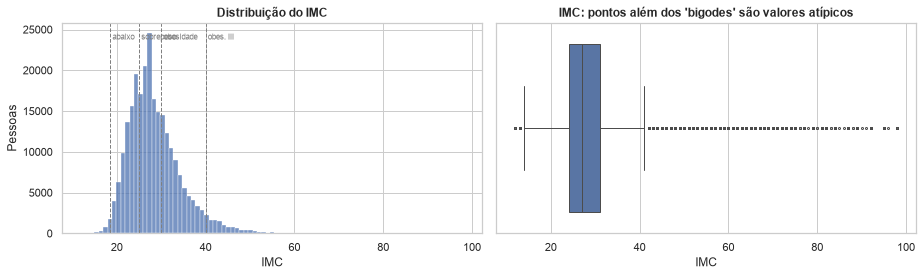

IMC ≥ 50: 2,547 pessoas (1.0%)  |  IMC ≥ 70: 599  |  máximo: 98


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.histplot(df["BMI"], bins=87, ax=axes[0], color="#4C72B0")
for limite, nome in [(18.5, "abaixo"), (25, "sobrepeso"), (30, "obesidade"), (40, "obes. III")]:
    axes[0].axvline(limite, ls="--", color="gray", lw=1)
    axes[0].text(limite + 0.5, axes[0].get_ylim()[1] * 0.92, nome, fontsize=8, color="gray")
axes[0].set(title="Distribuição do IMC", xlabel="IMC", ylabel="Pessoas")

sns.boxplot(x=df["BMI"], ax=axes[1], color="#4C72B0", fliersize=2)
axes[1].set(title="IMC: pontos além dos 'bigodes' são valores atípicos", xlabel="IMC")
plt.tight_layout()
plt.show()

print(
    f"IMC ≥ 50: {(df['BMI'] >= 50).sum():,} pessoas ({(df['BMI'] >= 50).mean():.1%})  |  "
    f"IMC ≥ 70: {(df['BMI'] >= 70).sum():,}  |  máximo: {df['BMI'].max():.0f}"
)

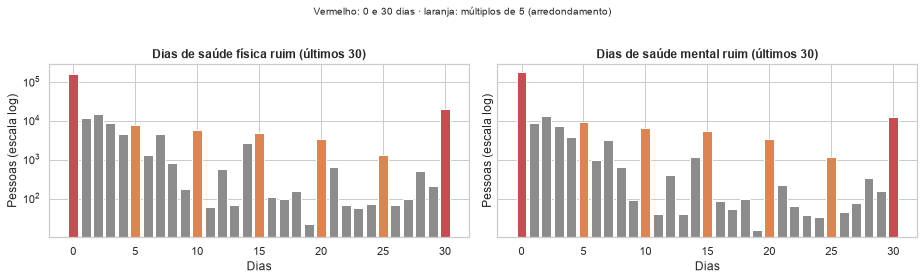

PhysHlth: 63% responderam 0 dias, 7.6% responderam 30
MentHlth: 69% responderam 0 dias, 4.8% responderam 30


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
for ax, col in zip(axes, ["PhysHlth", "MentHlth"], strict=True):
    contagem = df[col].value_counts().sort_index()
    cores = [
        "#C44E52" if v in (0, 30) else "#DD8452" if v % 5 == 0 else "#8C8C8C"
        for v in contagem.index
    ]
    ax.bar(contagem.index, contagem.values, color=cores)
    ax.set(
        title=f"{DESCRICAO[col]} (últimos 30)",
        xlabel="Dias",
        yscale="log",
        ylabel="Pessoas (escala log)",
    )
plt.suptitle(
    "Vermelho: 0 e 30 dias · laranja: múltiplos de 5 (arredondamento)", y=1.02, fontsize=10
)
plt.tight_layout()
plt.show()

for col in ["PhysHlth", "MentHlth"]:
    print(
        f"{col}: {(df[col] == 0).mean():.0%} responderam 0 dias, {(df[col] == 30).mean():.1%} responderam 30"
    )

📌 **O que observamos**

- **IMC:** a maioria está entre 24 e 31 (mediana 27, sobrepeso). Há uma cauda
  longa: ~1% tem IMC ≥ 50 e alguns chegam a 98. São valores *possíveis*, mas
  raros e possivelmente erros de digitação de peso/altura. Como os modelos de
  árvore são robustos a extremos, **mantivemos esses valores**; num modelo linear
  valeria limitá-los (*winsorizing*).
- **Dias ruins:** ~63% (física) e ~69% (mental) responderam **0 dias**, e há
  picos em **30** ("o mês todo") e em **múltiplos de 5** (5, 10, 15, 20). É o
  típico **arredondamento de memória** em pesquisas: ninguém lembra se foram 9
  ou 11 dias e responde "10". As variáveis são úteis, mas imprecisas.

## 3. A variável alvo

`Diabetes_012` tem três classes. Vamos ver o tamanho de cada uma e se faz
sentido juntar pré-diabetes e diabetes num alvo único de "risco".

,pessoas,% da base
classe,,
Sem diabetes,"213,703",84.2%
Pré-diabetes,"4,631",1.8%
Diabetes,"35,346",13.9%


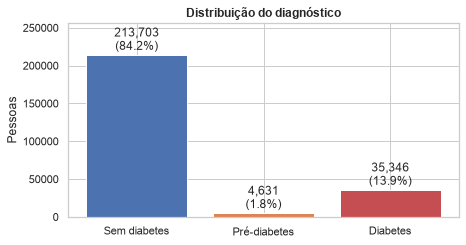

In [ ]:
contagem = df["classe"].value_counts().reindex(CLASS_ORDER)
tabela_alvo = pd.DataFrame({"pessoas": contagem, "% da base": contagem / len(df)})
display(formatar(tabela_alvo, gradiente=None))

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(contagem.index, contagem.values, color=[CLASS_COLORS[c] for c in contagem.index])
ax.bar_label(
    ax.containers[0], labels=[f"{v:,}\n({v / len(df):.1%})" for v in contagem.values], padding=2
)
ax.set(title="Distribuição do diagnóstico", ylabel="Pessoas", ylim=(0, contagem.max() * 1.2))
plt.show()

**O pré-diabetes é parecido com o quê?** Para cada variável, calculamos a média
em cada classe e a padronizamos (*z-score*: quantos desvios-padrão acima ou
abaixo da média geral). Cores quentes indicam valores acima da média.

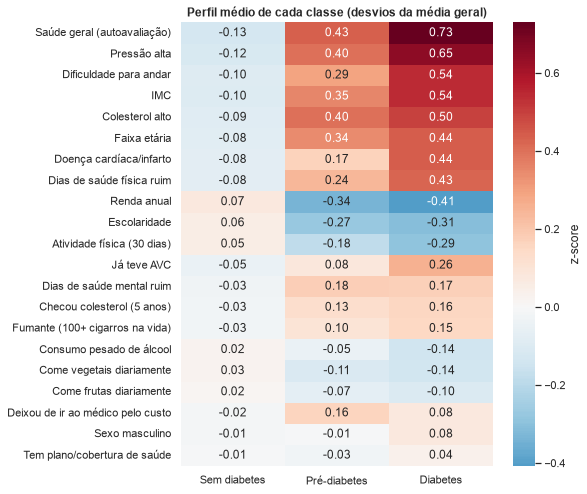

In [ ]:
medias = df.groupby("classe", observed=True)[features].mean()
padronizado = (medias - df[features].mean()) / df[features].std()
padronizado = padronizado.T.rename(index=DESCRICAO)
padronizado = padronizado.loc[padronizado["Diabetes"].abs().sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(7, 8))
sns.heatmap(
    padronizado,
    cmap="RdBu_r",
    center=0,
    annot=True,
    fmt=".2f",
    cbar_kws={"label": "z-score"},
    ax=ax,
)
ax.set(title="Perfil médio de cada classe (desvios da média geral)", xlabel="", ylabel="")
plt.show()

📌 **O que observamos**

- **84,2%** não têm diabetes, **13,9%** têm diabetes e só **1,8%** têm
  pré-diabetes (4.631 pessoas). A base é **desbalanceada**.
- O pré-diabetes é muito provavelmente **subnotificado**: ele não dá sintomas e só
  aparece em exames. Muita gente com pré-diabetes deve estar na classe "sem diabetes".
- No mapa de calor, o perfil do pré-diabetes fica **entre** os outros dois,
  porém **muito mais próximo do diabetes** (pressão alta, colesterol, saúde
  geral pior, mais velho, renda menor).

**Decisão para a modelagem:** juntar pré-diabetes e diabetes num alvo binário
de **"risco"** (1) contra "sem diabetes" (0). Isso faz sentido clínico (os dois
pedem intervenção) e estatístico (a classe de 1,8% sozinha seria quase
impossível de aprender). A partir daqui, **"% com risco"** = % de pré-diabetes + diabetes.

## 4. Retrato da população

Antes de cruzar com o diabetes, vale entender **quem respondeu** a pesquisa.

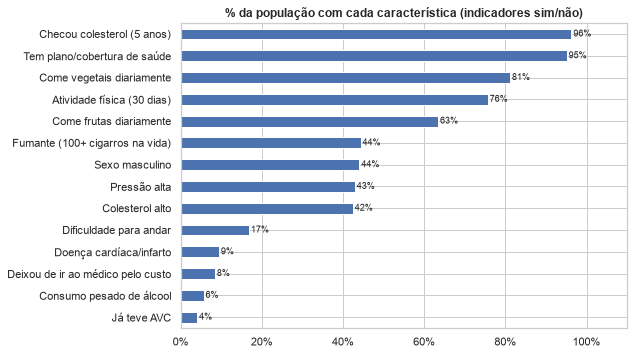

In [ ]:
freq = df[list(BINARY_FEATURES)].mean().rename(index=DESCRICAO).sort_values()

fig, ax = plt.subplots(figsize=(8, 5.5))
freq.plot.barh(ax=ax, color="#4C72B0")
rotular_barras(ax)
ax.set(
    title="% da população com cada característica (indicadores sim/não)", xlabel="", xlim=(0, 1.1)
)
ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
plt.show()

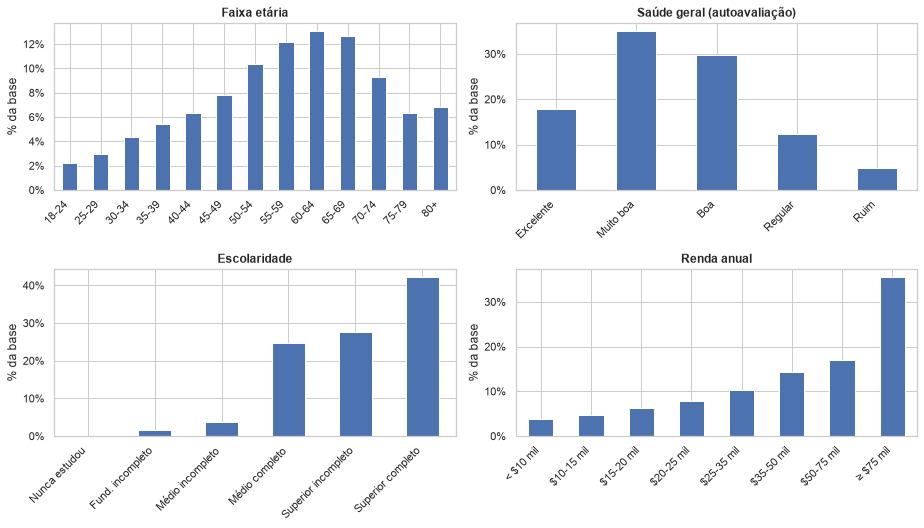

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(13, 7.5))
for ax, col in zip(axes.flat, ["Age", "GenHlth", "Education", "Income"], strict=True):
    dist = df[f"{col}_rotulo"].value_counts(normalize=True).sort_index()
    dist.plot.bar(ax=ax, color="#4C72B0", rot=45)
    ax.set(title=DESCRICAO[col], xlabel="", ylabel="% da base")
    ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
    for label in ax.get_xticklabels():
        label.set_horizontalalignment("right")
plt.tight_layout()
plt.show()

📌 **O que observamos**

- **Cobertura de saúde é quase universal** na amostra (95% têm plano e 96%
  checaram o colesterol): variáveis quase constantes informam pouco.
- **43% têm pressão alta** e **42% colesterol alto**, prevalências altas e
  típicas de uma população adulta mais velha.
- A amostra é **envelhecida** (pico entre 60 e 69 anos), com **escolaridade e
  renda altas** (a maior faixa de renda é a mais comum). Pesquisas telefônicas
  tendem a alcançar mais pessoas mais velhas e de maior renda.
- Só **5,6%** relatam consumo pesado de álcool e **4%** já tiveram AVC: grupos
  pequenos, cujas estatísticas são menos estáveis.

## 5. Agrupamentos: onde o diabetes se concentra

Aqui está o coração da análise: dividimos a população em grupos e comparamos a
**% com risco** (pré-diabetes + diabetes) entre eles. Na base inteira, essa taxa
é **15,8%**: grupos muito acima disso concentram risco.

### 5.1 Indicadores sim/não: quanto cada um multiplica o risco

Para cada indicador comparamos a % com risco de quem **tem** a característica
com a de quem **não tem**. A razão entre as duas é o **risco relativo (RR)**:

- **RR = 2** → quem tem a característica tem o dobro de prevalência;
- **RR = 1** → não faz diferença;
- **RR < 1** → a característica aparece mais entre quem *não* tem diabetes.

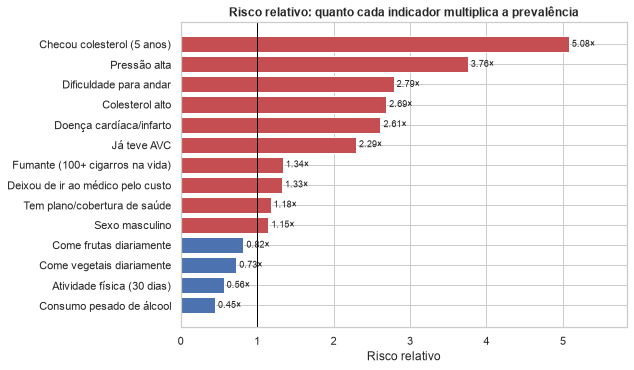

,% com risco (tem),% com risco (não tem),risco relativo
indicador,,,
Checou colesterol (5 anos),16.2%,3.2%,5.08×
Pressão alta,27.1%,7.2%,3.76×
Dificuldade para andar,33.8%,12.1%,2.79×
Colesterol alto,24.7%,9.2%,2.69×
Doença cardíaca/infarto,35.8%,13.7%,2.61×
Já teve AVC,34.3%,15.0%,2.29×
Fumante (100+ cigarros na vida),18.3%,13.7%,1.34×
Deixou de ir ao médico pelo custo,20.3%,15.3%,1.33×
Tem plano/cobertura de saúde,15.9%,13.5%,1.18×


In [ ]:
linhas = []
for col in BINARY_FEATURES:
    com, sem = df.loc[df[col] == 1, "tem_risco"].mean(), df.loc[df[col] == 0, "tem_risco"].mean()
    linhas.append(
        {
            "indicador": DESCRICAO[col],
            "% com risco (tem)": com,
            "% com risco (não tem)": sem,
            "risco relativo": com / sem,
        }
    )
rr = pd.DataFrame(linhas).set_index("indicador").sort_values("risco relativo")

fig, ax = plt.subplots(figsize=(8, 5.5))
cores = ["#C44E52" if v > 1 else "#4C72B0" for v in rr["risco relativo"]]
ax.barh(rr.index, rr["risco relativo"], color=cores)
ax.axvline(1, color="black", lw=1)
ax.bar_label(ax.containers[0], fmt="%.2f×", padding=3, fontsize=9)
ax.set(
    title="Risco relativo: quanto cada indicador multiplica a prevalência",
    xlabel="Risco relativo",
    xlim=(0, rr["risco relativo"].max() * 1.15),
)
plt.show()

formatar(rr.sort_values("risco relativo", ascending=False), gradiente="risco relativo").format(
    {"risco relativo": "{:.2f}×"}, subset=["risco relativo"]
)

📌 **O que observamos**

**Fatores fortemente associados (RR > 2):**
- **Pressão alta (3,8×)**: 27% de quem tem pressão alta tem diabetes/pré-diabetes,
  contra 7% de quem não tem. É o sinal mais forte entre os indicadores sim/não.
- **Dificuldade para andar (2,8×)**, **colesterol alto (2,7×)**, **doença cardíaca
  (2,6×)** e **AVC (2,3×)**: todos fazem parte da chamada *síndrome metabólica* e
  das complicações do diabetes.

**Hábitos saudáveis (RR < 1):** atividade física (0,56×), vegetais (0,73×) e
frutas (0,82×) aparecem mais entre quem não tem diabetes.

**⚠️ Dois resultados que enganam: atenção na interpretação**
- **Checou o colesterol (5,1×):** checar o colesterol não causa diabetes. Quem
  tem diabetes **vai mais ao médico** e faz mais exames: é um **viés de
  seleção/acompanhamento**. Note também que 96% checaram, então o grupo "não
  checou" é pequeno e atípico.
- **Consumo pesado de álcool (0,45×):** o álcool não protege contra diabetes.
  Pessoas diagnosticadas costumam **ser orientadas a parar de beber**: o
  diagnóstico muda o comportamento, e não o contrário (**causalidade reversa**).

Esses dois casos mostram por que um modelo preditivo pode usar uma variável
sem que ela seja uma causa, e por que não devemos tirar conclusões causais
desta base.

### 5.2 Idade

Como a prevalência de diabetes e de pré-diabetes muda ao longo da vida?

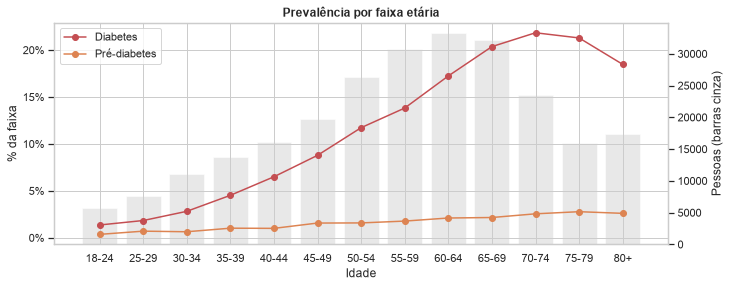

,pessoas,% da base,% com risco,% diabetes,% pré-diabetes
Age_rotulo,,,,,
18-24,"5,700",2.2%,1.7%,1.4%,0.4%
25-29,"7,598",3.0%,2.6%,1.8%,0.7%
30-34,"11,123",4.4%,3.5%,2.8%,0.6%
35-39,"13,823",5.4%,5.6%,4.5%,1.0%
40-44,"16,157",6.4%,7.5%,6.5%,1.0%
45-49,"19,819",7.8%,10.4%,8.8%,1.6%
50-54,"26,314",10.4%,13.3%,11.7%,1.6%
55-59,"30,832",12.2%,15.6%,13.8%,1.8%
60-64,"33,244",13.1%,19.4%,17.2%,2.1%


In [ ]:
por_idade = prevalencia(df, "Age_rotulo")

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(
    por_idade.index,
    por_idade["% diabetes"],
    marker="o",
    color=CLASS_COLORS["Diabetes"],
    label="Diabetes",
)
ax.plot(
    por_idade.index,
    por_idade["% pré-diabetes"],
    marker="o",
    color=CLASS_COLORS["Pré-diabetes"],
    label="Pré-diabetes",
)
ax2 = ax.twinx()
ax2.bar(por_idade.index, por_idade["pessoas"], color="lightgray", alpha=0.5, zorder=0)
ax2.set_ylabel("Pessoas (barras cinza)")
ax2.grid(False)
ax.set_zorder(ax2.get_zorder() + 1)
ax.patch.set_visible(False)
ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
ax.set(title="Prevalência por faixa etária", xlabel="Idade", ylabel="% da faixa")
ax.legend(loc="upper left")
plt.show()

formatar(por_idade)

📌 **O que observamos**

- A prevalência **cresce continuamente com a idade**: de **1,7%** (18–24 anos)
  para **~24%** (70–79 anos), cerca de 14× mais.
- A partir dos 50 anos o crescimento é mais acentuado; a faixa 60–64 já passa de 19%.
- **Queda após os 80 anos** (24% → 21%): provável **viés de sobrevivência**.
  Pessoas com diabetes tendem a viver menos, e quem chega aos 80+ é, em média,
  mais saudável. Pode haver também menor participação de idosos doentes na pesquisa.
- A curva de pré-diabetes é baixa em todas as idades, o que reforça a subnotificação.

### 5.3 Saúde geral, IMC, renda e escolaridade

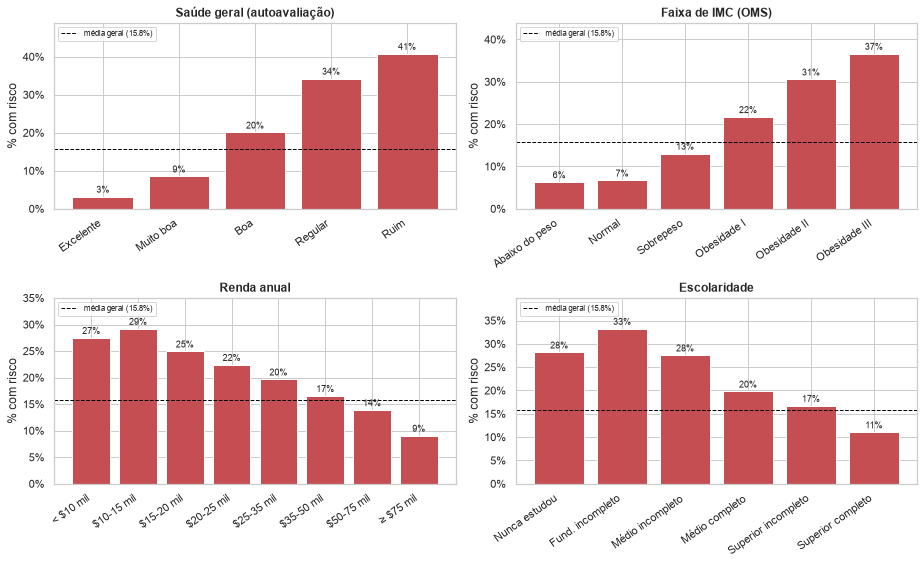

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
grupos = [
    ("GenHlth_rotulo", "Saúde geral (autoavaliação)"),
    ("faixa_imc", "Faixa de IMC (OMS)"),
    ("Income_rotulo", "Renda anual"),
    ("Education_rotulo", "Escolaridade"),
]
media_geral = df["tem_risco"].mean()

for ax, (col, titulo) in zip(axes.flat, grupos, strict=True):
    tabela = prevalencia(df, col)
    ax.bar(tabela.index.astype(str), tabela["% com risco"], color="#C44E52")
    ax.axhline(media_geral, ls="--", color="black", lw=1, label=f"média geral ({media_geral:.1%})")
    rotular_barras(ax)
    ax.set(title=titulo, ylabel="% com risco", ylim=(0, tabela["% com risco"].max() * 1.2))
    ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
    ax.tick_params(axis="x", rotation=35)
    for label in ax.get_xticklabels():
        label.set_horizontalalignment("right")
    ax.legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

In [ ]:
formatar(prevalencia(df, "faixa_imc"))

,pessoas,% da base,% com risco,% diabetes,% pré-diabetes
faixa_imc,,,,,
Abaixo do peso,"3,127",1.2%,6.3%,5.4%,0.9%
Normal,"68,953",27.2%,6.7%,5.7%,1.0%
Sobrepeso,"93,749",37.0%,13.0%,11.4%,1.6%
Obesidade I,"53,451",21.1%,21.7%,19.2%,2.5%
Obesidade II,"20,663",8.1%,30.6%,27.4%,3.1%
Obesidade III,"13,737",5.4%,36.6%,33.5%,3.1%


📌 **O que observamos**

- **Saúde geral** é o gradiente mais forte de toda a base: de **3%** entre quem
  diz ter saúde "excelente" para **41%** entre quem diz "ruim", **13× mais**.
  A autoavaliação resume muita informação: quem já tem diabetes percebe a
  própria saúde como pior.
- **IMC:** a prevalência sobe a cada faixa, de ~6% no peso normal para mais de
  30% na obesidade grau II e III. É uma relação de **dose-resposta**, como a
  medicina descreve: quanto maior o IMC, maior o risco.
- **Renda e escolaridade:** forte **gradiente socioeconômico**. Na menor renda,
  ~28% têm risco; na maior, 9%. Na escolaridade, de ~33% (fundamental
  incompleto) para 11% (superior completo). Renda e escolaridade não causam
  diabetes diretamente, mas refletem acesso a alimentação, saúde e tempo para
  atividade física. Os grupos de menor escolaridade são pequenos (veja a coluna "pessoas").

### 5.4 Efeito acumulado: quantos fatores de risco a pessoa tem

Contamos, para cada pessoa, quantos destes 5 fatores cardiometabólicos ela
tem: **pressão alta, colesterol alto, obesidade (IMC ≥ 30), sedentarismo e
doença cardíaca**. O risco cresce quando os fatores se somam?

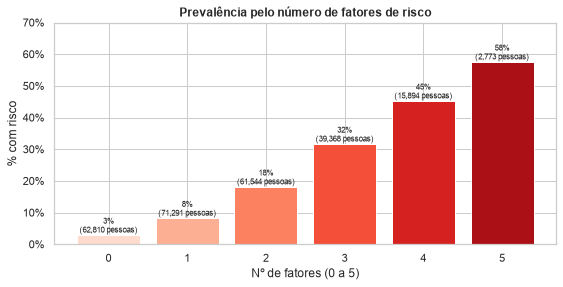

In [ ]:
df["n_fatores"] = (
    df["HighBP"]
    + df["HighChol"]
    + (df["BMI"] >= 30)
    + (1 - df["PhysActivity"])
    + df["HeartDiseaseorAttack"]
).astype(int)
por_fatores = prevalencia(df, "n_fatores")

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(
    por_fatores.index, por_fatores["% com risco"], color=sns.color_palette("Reds", len(por_fatores))
)
ax.bar_label(
    ax.containers[0],
    labels=[
        f"{p:.0%}\n({n:,} pessoas)"
        for p, n in zip(por_fatores["% com risco"], por_fatores["pessoas"], strict=True)
    ],
    fontsize=8,
)
ax.set(
    title="Prevalência pelo número de fatores de risco",
    xlabel="Nº de fatores (0 a 5)",
    ylabel="% com risco",
    ylim=(0, 0.7),
)
ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
plt.show()

📌 **O que observamos**

- O efeito é claramente **acumulativo**: cada fator a mais aumenta a
  prevalência de forma consistente. Sem nenhum fator, apenas **~3%** têm
  diabetes ou pré-diabetes; com 3 fatores, **~32%**; com os 5, **~58%**, cerca
  de **20× mais**.
- Poucas pessoas têm os 5 fatores (~2.800), mas o grupo com 3 ou mais é grande
  (~58 mil pessoas, 23% da base) e concentra risco alto.
- Isso sugere que **combinações** de variáveis explicam mais do que cada uma
  isolada, o que favorece modelos que capturam interações (como árvores de decisão).

### 5.5 Interações: combinações de características

**Idade × IMC:** o mapa mostra a % com risco em cada combinação de faixa
etária e faixa de IMC. Quanto mais escuro, maior a prevalência.

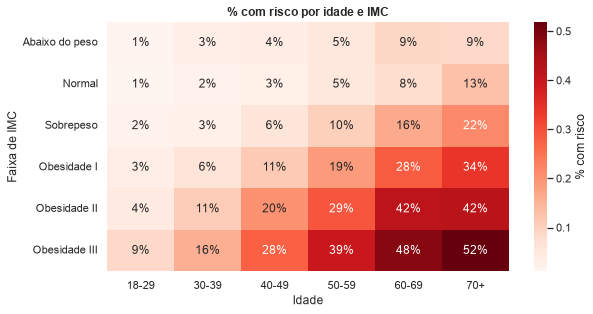

In [ ]:
df["idade_10"] = pd.cut(
    df["Age"],
    bins=[0, 2, 4, 6, 8, 10, 13],
    labels=["18-29", "30-39", "40-49", "50-59", "60-69", "70+"],
)
mapa = df.pivot_table(
    index="faixa_imc", columns="idade_10", values="tem_risco", aggfunc="mean", observed=True
)

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.heatmap(mapa, annot=True, fmt=".0%", cmap="Reds", cbar_kws={"label": "% com risco"}, ax=ax)
ax.set(title="% com risco por idade e IMC", xlabel="Idade", ylabel="Faixa de IMC")
plt.show()

In [ ]:
combo = (
    prevalencia(df, ["HighBP", "HighChol"])
    .rename(index=lambda v: "sim" if v == 1 else "não")
    .rename_axis(["Pressão alta", "Colesterol alto"])
)
formatar(combo)

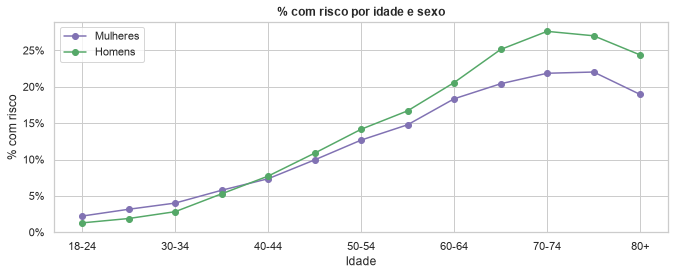

In [ ]:
por_sexo = df.pivot_table(
    index="Age_rotulo", columns="Sex", values="tem_risco", aggfunc="mean", observed=True
)
por_sexo.columns = ["Mulheres", "Homens"]

fig, ax = plt.subplots(figsize=(11, 3.8))
por_sexo.plot(ax=ax, marker="o", color=["#8172B3", "#55A868"])
ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
ax.set(title="% com risco por idade e sexo", xlabel="Idade", ylabel="% com risco")
plt.show()

📌 **O que observamos**

- **Idade e IMC se somam:** um jovem (18–29) com peso normal tem risco próximo
  de **1%**; uma pessoa com 70+ e obesidade grau III passa de **50%**. Nenhuma das
  duas variáveis sozinha mostra essa amplitude.
- **Pressão alta + colesterol alto:** quem tem os dois tem prevalência de
  **~33%**, contra **5%** de quem não tem nenhum (~6,5×). Ter só um deles fica no
  meio (12% só colesterol, 19% só pressão).
- **Sexo:** até os ~40 anos as mulheres têm prevalência levemente maior; a
  partir daí os homens passam à frente, e a diferença chega a ~5 pontos
  percentuais depois dos 65. Mesmo assim, o sexo pesa muito menos que a idade.

## 6. Correlações e associações

### 6.1 Quais variáveis andam juntas?

Usamos a **correlação de Spearman**, adequada para variáveis ordinais e
binárias. Ela vai de −1 (uma sobe, a outra desce) a +1 (sobem juntas); 0
indica ausência de relação monotônica. O mapa mostra só a metade inferior,
para não repetir valores.

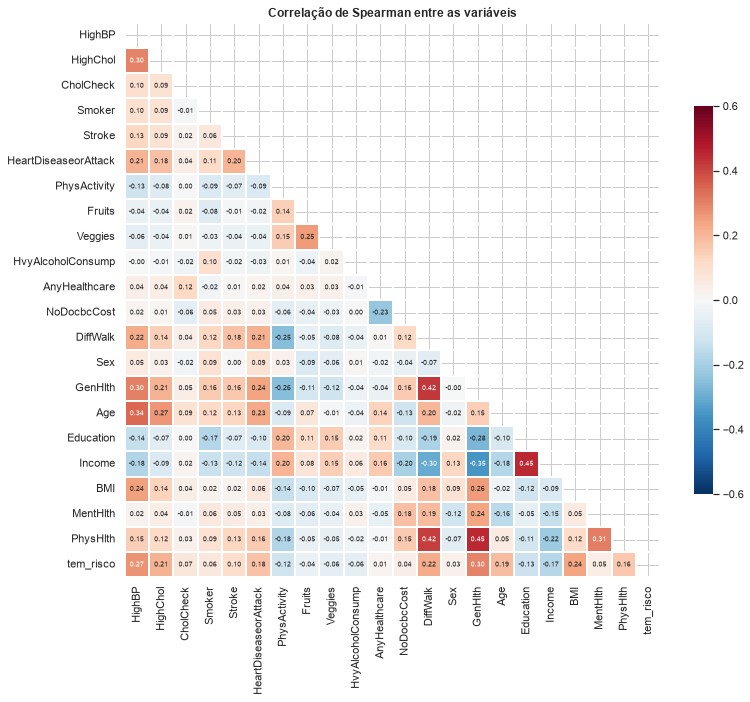

In [ ]:
corr = df[[*features, "tem_risco"]].corr(method="spearman")
mascara = np.triu(np.ones_like(corr, dtype=bool))

fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(
    corr,
    mask=mascara,
    cmap="RdBu_r",
    center=0,
    vmin=-0.6,
    vmax=0.6,
    annot=True,
    fmt=".2f",
    annot_kws={"fontsize": 7},
    linewidths=0.3,
    cbar_kws={"shrink": 0.7},
    ax=ax,
)
ax.set(title="Correlação de Spearman entre as variáveis")
plt.show()

In [ ]:
pares = corr.where(~mascara).stack().rename("correlação").reset_index()
pares["força"] = pares["correlação"].abs()
pares.sort_values("força", ascending=False).head(10).drop(columns="força").reset_index(drop=True)

,level_0,level_1,correlação
0,Income,Education,0.451978
1,PhysHlth,GenHlth,0.451847
2,GenHlth,DiffWalk,0.422791
3,PhysHlth,DiffWalk,0.415022
4,Income,GenHlth,-0.354253
5,Age,HighBP,0.344535
6,PhysHlth,MentHlth,0.308050
7,Income,DiffWalk,-0.303711
8,GenHlth,HighBP,0.303300
9,HighChol,HighBP,0.298199


### 6.2 O que mais informa sobre o alvo

Comparamos duas medidas de relação com o alvo:

- **Correlação de Spearman**: capta relações que sobem ou descem de forma consistente.
- **Informação mútua**: capta *qualquer* relação, inclusive não lineares (ex.: o risco
  sobe e depois cai). Vale 0 quando a variável não diz nada sobre o alvo.

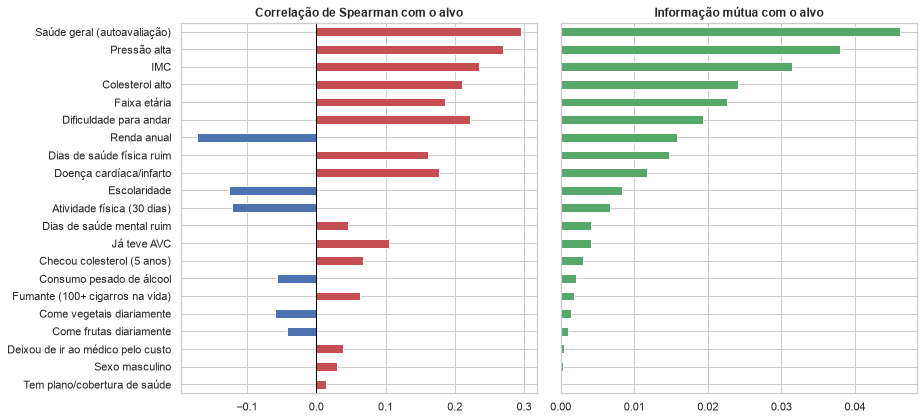

In [ ]:
from sklearn.feature_selection import mutual_info_classif

amostra = df.sample(60_000, random_state=SEED)
discretas = [c not in NUMERIC_FEATURES for c in features]
mi = mutual_info_classif(
    amostra[features], amostra["tem_risco"], discrete_features=discretas, random_state=SEED
)

relacao = (
    pd.DataFrame(
        {
            "correlação com o alvo": corr["tem_risco"].drop("tem_risco"),
            "informação mútua": pd.Series(mi, index=features),
        }
    )
    .rename(index=DESCRICAO)
    .sort_values("informação mútua")
)

fig, axes = plt.subplots(1, 2, figsize=(13, 6), sharey=True)
relacao["correlação com o alvo"].plot.barh(
    ax=axes[0], color=["#C44E52" if v > 0 else "#4C72B0" for v in relacao["correlação com o alvo"]]
)
axes[0].axvline(0, color="black", lw=1)
axes[0].set(title="Correlação de Spearman com o alvo", xlabel="")
relacao["informação mútua"].plot.barh(ax=axes[1], color="#55A868")
axes[1].set(title="Informação mútua com o alvo", xlabel="")
plt.tight_layout()
plt.show()

📌 **O que observamos**

- **As variáveis mais informativas** nas duas medidas são **saúde geral, pressão
  alta, IMC, idade, dificuldade de andar e colesterol alto**. Essa lista coincide
  com a importância por permutação do modelo treinado
  (`reports/figures/feature_importance.png`), o que dá confiança ao modelo.
- **Variáveis pouco informativas:** frutas, vegetais, plano de saúde, deixar de
  ir ao médico pelo custo e fumo. Não devem ser descartadas sem teste, mas
  contribuem pouco.
- **Variáveis redundantes:** saúde geral, dias de saúde física ruim e
  dificuldade de andar são correlacionadas entre si (~0,4–0,5); renda e
  escolaridade também (~0,45). Elas medem aspectos parecidos ("o quão debilitada
  está a saúde" e "nível socioeconômico"). Para árvores isso não é problema; num
  modelo linear, dificultaria interpretar os coeficientes.
- Nenhuma variável sozinha tem correlação alta com o alvo (máximo ~0,3): o
  diabetes depende de **várias coisas ao mesmo tempo**.

## 7. Perfis de pessoas

Duas abordagens complementares:

1. **Segmentação não supervisionada (K-Means):** agrupa as pessoas por
   semelhança **sem olhar o diagnóstico**. Pergunta: *existem "tipos" de pessoas?*
   Depois verificamos quanto diabetes há em cada tipo.
2. **Árvore de decisão rasa (supervisionada):** encontra as **regras simples**
   que melhor separam quem tem e quem não tem risco. Pergunta: *quais
   combinações concentram o risco?*

Nas duas usamos a base **sem duplicados**, para que os perfis repetidos não
pesem demais.

### 7.1 Segmentação com K-Means

Usamos 13 variáveis de saúde, estilo de vida e socioeconomia, padronizadas
para ficarem na mesma escala. Primeiro precisamos escolher **quantos grupos**
(k). Para isso usamos o **coeficiente de silhueta**, que mede o quanto cada
pessoa está mais próxima do próprio grupo do que dos outros (−1 a 1; acima de
0,5 indica grupos bem definidos; abaixo de 0,25, grupos sobrepostos).

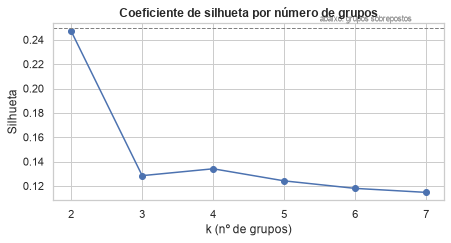

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

VARS_PERFIL = [
    "GenHlth",
    "PhysHlth",
    "MentHlth",
    "DiffWalk",
    "HighBP",
    "HighChol",
    "BMI",
    "Age",
    "Income",
    "Education",
    "PhysActivity",
    "HeartDiseaseorAttack",
    "Smoker",
]

unicos = df.drop_duplicates(subset=list(raw.columns)).reset_index(drop=True)
X_perfil = StandardScaler().fit_transform(unicos[VARS_PERFIL])

rng = np.random.default_rng(SEED)
idx = rng.choice(len(X_perfil), 20_000, replace=False)
silhuetas = {}
for k in range(2, 8):
    rotulos = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit_predict(X_perfil[idx])
    silhuetas[k] = silhouette_score(X_perfil[idx], rotulos, sample_size=8_000, random_state=SEED)

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(list(silhuetas), list(silhuetas.values()), marker="o")
ax.axhline(0.25, ls="--", color="gray", lw=1)
ax.text(5.5, 0.255, "abaixo: grupos sobrepostos", fontsize=8, color="gray")
ax.set(
    title="Coeficiente de silhueta por número de grupos",
    xlabel="k (nº de grupos)",
    ylabel="Silhueta",
)
plt.show()

A silhueta é **baixa para qualquer k** (≤ 0,25): **não existem grupos naturais
bem separados**. As pessoas variam num **contínuo** (de "muito saudável" a "muito
doente"), sem fronteiras nítidas. Isso é comum em dados de saúde.

Ainda assim, a segmentação é útil como **resumo descritivo**. Escolhemos
**k = 4**, que equilibra interpretabilidade e detalhe (k = 2 só separaria
"saudáveis" de "não saudáveis"). Os nomes dos perfis são atribuídos
automaticamente pelas características de cada grupo.

In [ ]:
kmeans = KMeans(n_clusters=4, n_init=10, random_state=SEED).fit(X_perfil)
unicos["grupo"] = kmeans.labels_

perfil = unicos.groupby("grupo").agg(
    pessoas=("tem_risco", "size"),
    **{"% com risco": ("tem_risco", "mean")},
    **{c: (c, "mean") for c in VARS_PERFIL},
)
perfil["% da base"] = perfil["pessoas"] / len(unicos)


def nomear_perfis(tabela: pd.DataFrame) -> dict[int, str]:
    # Menor risco = saudáveis; maior risco = saúde comprometida; entre os dois do meio,
    # o com menos atividade física é o "sedentário".
    ordem = tabela["% com risco"].sort_values().index.tolist()
    meio = sorted(ordem[1:3], key=lambda g: tabela.loc[g, "PhysActivity"])
    return {
        ordem[0]: "Jovens saudáveis e ativos",
        meio[0]: "Sedentários",
        meio[1]: "Ativos com comorbidades",
        ordem[3]: "Saúde comprometida",
    }


nomes = nomear_perfis(perfil)
perfil = perfil.rename(index=nomes).sort_values("% com risco")
unicos["perfil"] = unicos["grupo"].map(nomes)

legivel = perfil[["pessoas", "% da base", "% com risco"]].join(
    perfil[VARS_PERFIL].rename(columns=DESCRICAO).round(2)
)
formatar(legivel)

,pessoas,% da base,% com risco,Saúde geral (autoavaliação),Dias de saúde física ruim,Dias de saúde mental ruim,Dificuldade para andar,Pressão alta,Colesterol alto,IMC,Faixa etária,Renda anual,Escolaridade,Atividade física (30 dias),Doença cardíaca/infarto,Fumante (100+ cigarros na vida)
grupo,,,,,,,,,,,,,,,,
Jovens saudáveis e ativos,"84,890",36.9%,4.6%,2.03,1.63,2.60,0.02,0.07,0.18,26.90,6.14,6.65,5.31,0.97,0.01,0.34
Sedentários,"41,003",17.8%,18.4%,2.63,2.18,2.30,0.14,0.49,0.46,29.72,8.51,5.75,4.77,0.00,0.07,0.49
Ativos com comorbidades,"68,993",30.0%,22.2%,2.56,1.90,1.55,0.10,0.78,0.66,28.91,9.75,5.96,4.98,1.00,0.14,0.53
Saúde comprometida,"34,895",15.2%,37.0%,4.05,20.51,10.99,0.80,0.70,0.62,31.37,9.04,4.06,4.45,0.49,0.30,0.63


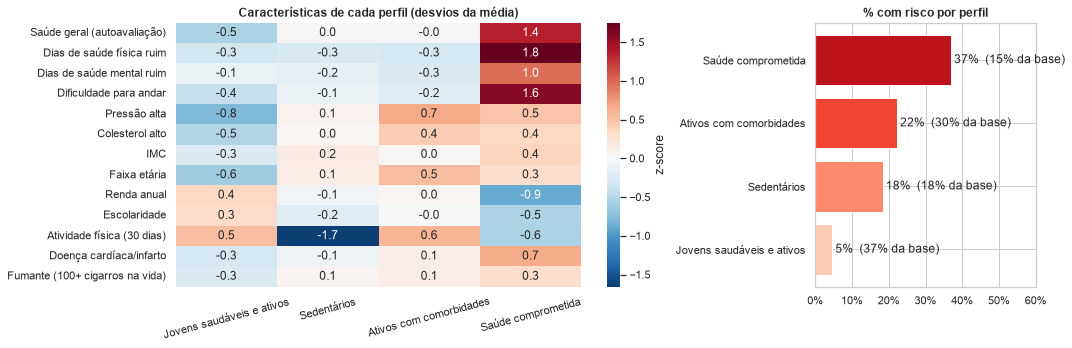

In [ ]:
z = (perfil[VARS_PERFIL] - unicos[VARS_PERFIL].mean()) / unicos[VARS_PERFIL].std()

fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [2.3, 1]})
sns.heatmap(
    z.T.rename(index=DESCRICAO),
    cmap="RdBu_r",
    center=0,
    annot=True,
    fmt=".1f",
    cbar_kws={"label": "z-score"},
    ax=axes[0],
)
axes[0].set(title="Características de cada perfil (desvios da média)", xlabel="", ylabel="")
axes[0].tick_params(axis="x", rotation=15)

axes[1].barh(perfil.index, perfil["% com risco"], color=sns.color_palette("Reds", 4))
axes[1].bar_label(
    axes[1].containers[0],
    labels=[
        f"{p:.0%}  ({s:.0%} da base)"
        for p, s in zip(perfil["% com risco"], perfil["% da base"], strict=True)
    ],
    padding=3,
)
axes[1].set(title="% com risco por perfil", xlim=(0, 0.6))
axes[1].xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
plt.tight_layout()
plt.show()

**Visualizando os perfis em 2D.** O PCA comprime as 13 variáveis em 2 eixos,
preservando o máximo possível da variação, para podermos "ver" os grupos.

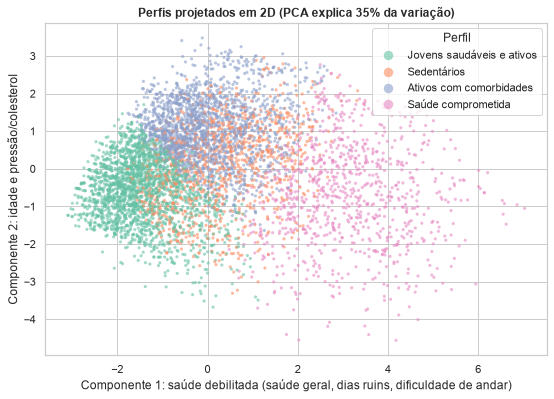

In [ ]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=SEED).fit(X_perfil[idx])
pontos = idx[:6_000]  # 6 mil pontos bastam para ver a forma e mantêm o gráfico leve
coords = pca.transform(X_perfil[pontos])
amostra_perfil = unicos.iloc[pontos]

fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(
    x=coords[:, 0],
    y=coords[:, 1],
    hue=amostra_perfil["perfil"].values,
    hue_order=perfil.index,
    palette="Set2",
    s=10,
    alpha=0.6,
    linewidth=0,
    ax=ax,
)
ax.set(
    title=f"Perfis projetados em 2D (PCA explica {pca.explained_variance_ratio_.sum():.0%} da variação)",
    xlabel="Componente 1: saúde debilitada (saúde geral, dias ruins, dificuldade de andar)",
    ylabel="Componente 2: idade e pressão/colesterol",
)
ax.legend(title="Perfil", markerscale=3)
plt.show()

📌 **O que observamos: 4 perfis**

| Perfil | Tamanho | % com risco | Como reconhecer |
|---|---|---|---|
| **Jovens saudáveis e ativos** | ~37% | **~5%** | Mais jovens, saúde muito boa, quase sem pressão alta, ativos, renda e escolaridade altas |
| **Sedentários** | ~18% | **~18%** | **Nenhuma atividade física**; o resto perto da média |
| **Ativos com comorbidades** | ~30% | **~22%** | Mais velhos, **pressão e colesterol altos**, mas ativos e com saúde geral razoável |
| **Saúde comprometida** | ~15% | **~37%** | **~20 dias de saúde física ruim/mês**, 80% com dificuldade de andar, saúde regular/ruim, renda baixa, mais doença cardíaca |

- O risco varia **~8×** entre o perfil mais saudável e o mais comprometido.
- O perfil **"Saúde comprometida"** é pequeno (15%), mas concentra o maior
  risco: é o alvo natural de uma triagem prioritária.
- **"Ativos com comorbidades"** mostra que ser ativo não basta: a idade e a
  pressão alta pesam mais.
- No gráfico 2D os grupos **se sobrepõem**, como a silhueta indicou: são faixas
  de um contínuo, não "ilhas" separadas. O eixo horizontal resume o quão
  debilitada está a saúde (e renda menor); o vertical, idade e condições
  cardiometabólicas. Os 2 eixos explicam juntos ~35% da variação.

### 7.2 Regras que concentram o risco (árvore de decisão)

Uma árvore de decisão com **3 níveis** faz perguntas sucessivas ("tem pressão
alta?", "a saúde é regular ou ruim?") e divide a população em **8 segmentos**.
Exigimos ao menos 3.000 pessoas por segmento para que as taxas sejam confiáveis.
A tabela traduz cada segmento numa regra legível.

In [ ]:
from sklearn.tree import DecisionTreeClassifier

arvore = DecisionTreeClassifier(max_depth=3, min_samples_leaf=3_000, random_state=SEED)
arvore.fit(unicos[features], unicos["tem_risco"])


def nome_curto(col: str) -> str:
    nome = DESCRICAO[col].split(" (")[0]
    return nome if nome.isupper() else nome[0].lower() + nome[1:]


def descrever(col: str, minimo: float, maximo: float) -> str:
    # Converte o intervalo (minimo, maximo] de uma variável em texto legível.
    nome = nome_curto(col)
    if col in BINARY_FEATURES:
        return f"{'com' if minimo >= 0.5 else 'sem'} {nome}"
    if col in ORDINAL_LABELS:
        rotulos = ORDINAL_LABELS[col]
        de = rotulos[int(np.ceil(minimo))] if np.isfinite(minimo) else None
        ate = rotulos[int(np.floor(maximo))] if np.isfinite(maximo) else None
        if de and ate:
            return f"{nome} = {de}" if de == ate else f"{nome} entre {de} e {ate}"
        return f"{nome} ≥ {de}" if de else f"{nome} ≤ {ate}"
    if np.isfinite(minimo) and np.isfinite(maximo):
        return f"{nome} entre {minimo:g} e {maximo:g}"
    return f"{nome} > {minimo:g}" if np.isfinite(minimo) else f"{nome} ≤ {maximo:g}"


def extrair_segmentos(modelo, colunas) -> list[tuple[int, list[str]]]:
    # Percorre a árvore guardando, para cada variável, o intervalo permitido até cada folha.
    t = modelo.tree_
    segmentos = []

    def visitar(no: int, limites: dict[str, tuple[float, float]]) -> None:
        if t.children_left[no] == -1:  # folha: descreve as condições acumuladas
            segmentos.append((no, [descrever(c, lo, hi) for c, (lo, hi) in limites.items()]))
            return
        col, corte = colunas[t.feature[no]], t.threshold[no]
        lo, hi = limites.get(col, (-np.inf, np.inf))
        visitar(t.children_left[no], {**limites, col: (lo, min(hi, corte))})
        visitar(t.children_right[no], {**limites, col: (max(lo, corte), hi)})

    visitar(0, {})
    return segmentos


folhas = arvore.apply(unicos[features])
media_risco = unicos["tem_risco"].mean()
segmentos = pd.DataFrame(
    [
        {
            "regra": " · ".join(regras),
            "pessoas": (folhas == no).sum(),
            "% da base": (folhas == no).mean(),
            "% com risco": unicos.loc[folhas == no, "tem_risco"].mean(),
        }
        for no, regras in extrair_segmentos(arvore, features)
    ]
)
segmentos["× a média"] = segmentos["% com risco"] / media_risco
segmentos = segmentos.sort_values("% com risco", ascending=False).reset_index(drop=True)
formatar(segmentos).format({"× a média": "{:.1f}×"}, subset=["× a média"])

,regra,pessoas,% da base,% com risco,× a média
0,com pressão alta · saúde geral ≥ Regular · IMC > 27.5,"18,927",8.2%,50.5%,2.9×
1,com pressão alta · saúde geral ≥ Regular · IMC ≤ 27.5,"9,967",4.3%,30.6%,1.8×
2,com pressão alta · saúde geral = Boa,"38,111",16.6%,28.7%,1.7×
3,sem pressão alta · saúde geral ≥ Boa · com colesterol alto,"18,315",8.0%,21.0%,1.2×
4,com pressão alta · saúde geral ≤ Muito boa,"37,417",16.3%,15.4%,0.9×
5,sem pressão alta · saúde geral ≥ Boa · sem colesterol alto,"32,018",13.9%,10.6%,0.6×
6,sem pressão alta · saúde geral ≤ Muito boa · faixa etária ≥ 60-64,"25,846",11.2%,7.4%,0.4×
7,sem pressão alta · saúde geral ≤ Muito boa · faixa etária ≤ 55-59,"49,180",21.4%,2.6%,0.1×


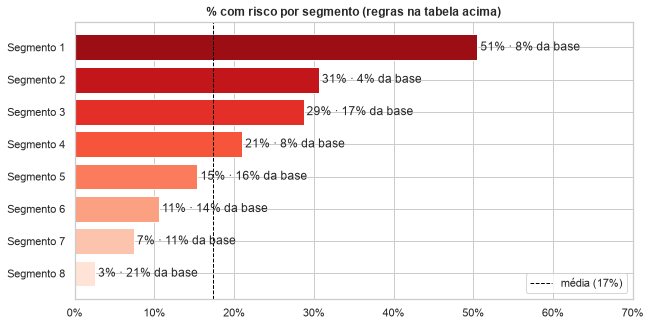

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))
ordem = segmentos.iloc[::-1]
ax.barh(range(len(ordem)), ordem["% com risco"], color=sns.color_palette("Reds", len(ordem)))
ax.set_yticks(range(len(ordem)), [f"Segmento {i + 1}" for i in ordem.index])
ax.axvline(media_risco, ls="--", color="black", lw=1, label=f"média ({media_risco:.0%})")
ax.bar_label(
    ax.containers[0],
    labels=[
        f"{p:.0%} · {s:.0%} da base"
        for p, s in zip(ordem["% com risco"], ordem["% da base"], strict=True)
    ],
    padding=3,
)
ax.set(title="% com risco por segmento (regras na tabela acima)", xlim=(0, 0.7))
ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
ax.legend(loc="lower right")
plt.show()

📌 **O que observamos**

- **Segmento de maior risco (~50%):** pessoas **com pressão alta**, saúde geral
  **regular ou ruim** e **IMC acima de 27,5**. Metade delas tem diabetes ou
  pré-diabetes, **~3× a média**.
- **Segmento de menor risco (~2,6%):** **sem pressão alta**, saúde **excelente ou
  muito boa** e **menos de 60 anos**. É o maior segmento (~21% da base).
- A árvore escolheu sozinha **pressão alta** como primeira pergunta e **saúde
  geral** como segunda, confirmando a análise de risco relativo e de informação
  mútua.
- Com apenas **3 perguntas**, a prevalência já vai de **3% a 50%** entre
  segmentos. Isso mostra o potencial de uma triagem simples e explica por que o
  modelo completo atinge ROC-AUC ≈ 0,81.

## 8. Conclusões e implicações

### O que aprendemos sobre os dados

| Tema | Achado | Implicação para o projeto |
|---|---|---|
| **Desbalanceamento** | 84% sem diabetes; pré-diabetes = 1,8% | Alvo binário (pré-diabetes + diabetes); `class_weight="balanced"`; métricas focadas na classe positiva (recall, PR-AUC), não acurácia |
| **Duplicados** | 9,4% das linhas; 99% são saudáveis "típicos" | Remover **antes** do split para evitar vazamento; a prevalência sobe de 15,8% para 17,3% |
| **Rótulos conflitantes** | 2,4% das pessoas têm "gêmeos" com outro diagnóstico | Há um teto de desempenho; não esperar acerto perfeito |
| **Respostas arredondadas** | Picos em 0, 30 e múltiplos de 5 nos dias ruins | Variáveis úteis, mas ruidosas; árvores lidam bem com isso |
| **IMC extremo** | ~1% com IMC ≥ 50, máximo 98 | Mantido (árvores são robustas); limitar se usar modelo linear |
| **Fatores principais** | Saúde geral, pressão alta, IMC, idade, dificuldade de andar, colesterol | Coincidem com a importância do modelo, uma validação cruzada da análise |
| **Interações** | Riscos se somam (idade × IMC; pressão × colesterol) | Modelos baseados em árvores (como o `HistGradientBoosting` usado) capturam isso naturalmente |
| **Causalidade reversa** | Álcool "protege"; checar colesterol "aumenta" risco | O modelo pode usar essas variáveis para **prever**, mas não se deve recomendar condutas com base nelas |
| **Perfis** | Contínuo sem grupos naturais; 4 perfis de 5% a 37%; regras de 3% a 50% | Triagem por segmentos é viável; o perfil "Saúde comprometida" é prioritário |

### Limitações da base

- **Autodeclarada:** depende da memória e da sinceridade do entrevistado; quem
  nunca fez exame não sabe que tem diabetes (subnotificação).
- **Transversal:** é uma "foto" de 2015, sem acompanhamento no tempo. Não dá para
  saber o que veio antes, o fator ou o diagnóstico.
- **População dos EUA, pesquisa por telefone:** amostra mais velha e de renda
  maior; os resultados podem não se generalizar para outras populações.

### Próximas investigações sugeridas

1. Repetir a análise **separando pré-diabetes de diabetes**, para entender se
   há sinais específicos do estágio inicial.
2. Comparar com os anos seguintes do BRFSS para avaliar **drift** (mudança no
   perfil da população ao longo do tempo).
3. Investigar a **calibração por perfil**: o modelo erra mais em algum dos 4 perfis?
4. Avaliar **equidade (fairness)**: o desempenho do modelo é o mesmo entre
   sexos, faixas de renda e de escolaridade?